### Simple Multi AI Agent

In [1]:
import os
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain.agents import create_agent
from langchain_tavily import TavilySearch
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
os.environ['OPENAI_API_KEY']=os.getenv("OPEN_API_KEY")
os.environ['TAVILY_API_KEY']=os.getenv("TAVILY_API_KEY")

In [3]:
class AgentState(MessagesState):
    nextAgnet: str #Tells which agent should be invoked next

In [4]:
@tool
def search_web(query:str) -> str:
    """Search in the web for any information"""
    #Using tavily API to search in the web
    search = TavilySearch(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content:str) -> str:
    """Write a summary of the provided content."""
    #Simple summary generation
    summary = f"Summary of findings: \n\n{content[:500]}..."
    return summary

In [5]:
llm = ChatOpenAI(model="gpt-4o-mini")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7', 'langchain-openai': '1.7.2'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001DF106812D0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000001DF111A11D0>, root_client=<openai.OpenAI object at 0x000001DF11104D50>

In [6]:
# Define agent functions
def researcher_agent(state:AgentState):
    """Researcher agent that searches for information"""

    messages = state['messages']

    #Add system message for context
    system_msg = SystemMessage(content="You are a research Assistant. Use the search_web tool to find the information about the user's request")

    #Call LLM with tools
    tools=[search_web]
    researcher_llm = llm.bind_tools(tools)
    response = researcher_llm.invoke([system_msg] + messages)

    #Return the response and route to writer
    return {
        "messages":[response],
        "next_agent":"writer"
    }


In [7]:
def writer_agent(state:AgentState):
    """Writer agent that creates summaries"""

    messages = state['messages']

    #Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")

    #simple completion without tools
    response = llm.invoke([system_msg]+messages)

    return {
        "messages":[response],
        "next_agent":"end"
    }

In [8]:
#Tool executor node
def execute_tools(state:AgentState):
    """Execute any pending tool calls"""
    messages = state['messages']
    last_message = messages[-1]

    #check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        #Create tool noe and execute
        tool_node = ToolNode([search_web])
        response = tool_node.invoke(state)
        return response

    #No Tools to execute
    return state

In [9]:
def route_after_research(state: AgentState) -> str:
    """Run requested tools before passing the conversation to the writer."""
    last_message = state["messages"][-1]
    if isinstance(last_message, AIMessage) and last_message.tool_calls:
        return "execute_tools"
    return "writer"


# Initialize graph

workflow = StateGraph(MessagesState)

#Add nodes
workflow.add_node("researcher",researcher_agent)
workflow.add_node("execute_tools", execute_tools)
workflow.add_node("writer", writer_agent)

#Define flow
# Execute every requested tool before the writer sees the conversation.
workflow.set_entry_point("researcher")
workflow.add_conditional_edges(
    "researcher",
    route_after_research,
    {"execute_tools": "execute_tools", "writer": "writer"},
)
workflow.add_edge("execute_tools", "writer")
workflow.add_edge("writer", END)

final_workflow = workflow.compile()

print(final_workflow)

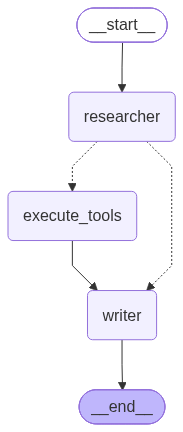

In [10]:
final_workflow

In [11]:
response = final_workflow.invoke({"messages":"Research about the usecase of Agentic AI in business"})
response

{'messages': [HumanMessage(content='Research about the usecase of Agentic AI in business', additional_kwargs={}, response_metadata={}, id='17099f90-f1ef-4440-944b-ac4113789060'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 76, 'total_tokens': 96, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_80c9d72b86', 'id': 'chatcmpl-EeHmmzdpyoxPQ1jyAjvT3Fw9q3L2x', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1873b-a46d-770d-8199-c621487e34dd-0', tool_calls=[{'name': 'search_web', 'args': {'query': 'Agentic AI use case in

In [12]:
response['messages'][-1].pretty_print()

================================== Ai Message ==================================

Agentic AI, which refers to autonomous systems capable of performing complex business tasks without human intervention, is increasingly adopted across various industries due to its ability to bridge digital fragmentation and enhance decision-making processes. Here are the key findings regarding its use cases in business:

1. **Automation and Efficiency**: Agentic AI helps automate high-volume and decision-intensive processes, improving efficiency by handling tasks that previously required human input, such as fraud detection in banking and patient monitoring in healthcare.

2. **Adaptability**: These AI agents have the ability to learn from new information and past outcomes, continuously improving their performance without needing reprogramming.

3. **Collaborative Functionality**: Agentic AI systems can operate either autonomously or in collaboration with human users, enhancing operational workflows by i